# JEPA as a Volatility Estimator for Deep Hedging

## Thesis Experiment 3: Can JEPA's inferred variance substitute for true variance in Buehler's hedging network?

### The Setup

Buehler et al. (2019) train a deep hedging network that at each timestep $t$ receives the **true** Heston variance $V_t$ as part of its state vector:

$$s_t = [S_t,\ V_t,\ \text{VarSwap}_t,\ \tau_t]$$

In practice, $V_t$ is **latent** — a real trader cannot observe it. This notebook answers:

> *If we replace $V_t$ with $\hat{V}_t$ predicted by our frozen JEPA encoder, how close does the hedging performance get to the oracle (true $V_t$) benchmark?*

### Three conditions compared

| Condition | What goes into $s_t$ | What it represents |
|-----------|---------------------|--------------------|
| **Oracle** | True $V_t$ | Buehler's original — upper bound |
| **JEPA** | $\hat{V}_t$ from JEPA linear probe | Our contribution |
| **No-Vol** | $V_t$ replaced by 0 | Ablation — what if we give the hedger no variance info? |
| **Analytical Delta** | Fang-Oosterlee COS pricer | Buehler's paper benchmark — no learning needed |

### Metric
Mean hedging P&L (terminal wealth), its standard deviation, and the OCE (Optimised Certainty Equivalent) risk measure used in Buehler's paper:
$$\text{OCE} = -\mathbb{E}[\ell(W_T)]$$
where $W_T$ is terminal hedged wealth and $\ell$ is a convex loss (here: $\ell(x) = -x + \alpha \cdot \max(-x, 0)$ with $\alpha=0.5$ matching Buehler's reference experiment).

## 0. Imports and setup

In [1]:
import sys, os
sys.path.insert(0, os.path.join('..'))          # project root

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from tqdm.notebook import tqdm

from heston_sim.generate import load_split
from jepa.dataset        import HestonWindowDataset
from jepa.model          import HestonJEPA

# Also import Heston parameters for the analytical delta benchmark
REPO_ROOT = os.path.join('..', 'deep-hedging-heston')
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)
from deep_hedging_heston.parameters import HestonParameters
from deep_hedging_heston.pricers    import heston_call_deltas, model_deltas_on_paths

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')

# Reproducibility
torch.manual_seed(0)
np.random.seed(0)

C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\google\api_core\_python_version_support.py:223: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)


Device: cuda


## 1. Load data and JEPA model

In [2]:
# ── Load test paths ────────────────────────────────────────────────────────
test_data = load_split('test', data_dir='../data')

stocks        = test_data['stocks']        # (N, T+1)
log_returns   = test_data['log_returns']   # (N, T)
variance      = test_data['variance']      # (N, T+1)  ← oracle V_t
variance_swap = test_data['variance_swap'] # (N, T+1)
payoff        = test_data['payoff']        # (N,)

N, T_plus1 = stocks.shape
T = T_plus1 - 1
print(f'Test paths: {N:,}   Timesteps: {T}')

heston_params = HestonParameters()
print(f'Strike K={heston_params.K}, S0={heston_params.S0}, T={heston_params.T:.4f}, timesteps={heston_params.timesteps}')

Test paths: 50,000   Timesteps: 30
Strike K=100, S0=100, T=0.0822, timesteps=30


In [3]:
# ── Load frozen JEPA encoder ───────────────────────────────────────────────
CHECKPOINT  = '../checkpoints/jepa_prices.pt'
CONTEXT_LEN = 10
TARGET_LEN  = 5

ckpt   = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=False)
config = ckpt['config']

jepa = HestonJEPA(
    feature_dim   = config['feature_dim'],
    d_model       = config['d_model'],
    n_heads       = config['n_heads'],
    n_layers      = config['n_layers'],
    ema_momentum  = config['ema_momentum'],
    var_reg_coeff = config['var_reg_coeff'],
).to(DEVICE)
jepa.load_state_dict(ckpt['model_state'])
jepa.eval()
print(f'JEPA loaded  (val_loss={ckpt["val_loss"]:.4f})')

JEPA loaded  (val_loss=0.0106)


c:\Users\USER\OneDrive\Desktop\IIT\Thesis\Implementation\Git Repo\JEPA---Deep-Hedging\Vibe coded experiment 2\Jepa-Heston\notebooks\..\jepa\encoder.py:94: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


## 2. Build JEPA variance estimates for every timestep

For each path and each timestep $t \geq L$ (where $L$ = `CONTEXT_LEN`), we encode the window $[t-L, t)$ of log returns and pass the embedding through the linear probe to get $\hat{V}_t$.

For $t < L$ (the first few steps where we don't have a full context window), we fall back to the unconditional mean of $V_t$ from training data.

In [4]:
# ── Step 2a: Fit the linear probe on training embeddings ───────────────────
# (same as probes/volatility_probe.py — we re-fit here for self-containedness)

print('Fitting linear probe on training data ...')
train_data = load_split('train', data_dir='../data')

sub_idx   = np.random.default_rng(42).choice(
    train_data['log_returns'].shape[0], size=50_000, replace=False
)
train_sub = {k: v[sub_idx] for k, v in train_data.items()}

train_ds  = HestonWindowDataset(train_sub, CONTEXT_LEN, TARGET_LEN, mode='prices')
train_ld  = DataLoader(train_ds, batch_size=2048, shuffle=False, num_workers=0)

Z_tr, V_tr = [], []
jepa.eval()
with torch.no_grad():
    for batch in tqdm(train_ld, desc='Encoding train'):
        z = jepa.encode(batch['context'].to(DEVICE))
        Z_tr.append(z.cpu().numpy())
        V_tr.append(batch['target_variance'].numpy())

Z_tr = np.concatenate(Z_tr)
V_tr = np.concatenate(V_tr)

scaler = StandardScaler()
probe  = Ridge(alpha=1.0)
probe.fit(scaler.fit_transform(Z_tr), V_tr)
print(f'Probe fitted on {len(Z_tr):,} samples')

Fitting linear probe on training data ...


Encoding train:   0%|          | 0/391 [00:00<?, ?it/s]

Probe fitted on 800,000 samples


In [5]:
# ── Step 2b: Infer V̂_t for every (path, t) in the test set ───────────────
# Shape goal: (N, T+1) — matching variance array exactly

print('Inferring JEPA variance for all test paths ...')

V_fallback = float(V_tr.mean())   # used for t < CONTEXT_LEN

V_jepa = np.full_like(variance, V_fallback)   # (N, T+1), initialised to mean

# For each valid t, build the context window in batch
# t runs from CONTEXT_LEN to T (inclusive)
batch_size = 4096

for t in tqdm(range(CONTEXT_LEN, T + 1), desc='Inferring V̂_t'):
    # Context window: log_returns[:, t-L : t]  shape (N, L)
    ctx_np  = log_returns[:, t - CONTEXT_LEN : t][:, :, np.newaxis]  # (N, L, 1)
    n_total = ctx_np.shape[0]
    preds   = []

    for start in range(0, n_total, batch_size):
        ctx_t = torch.tensor(ctx_np[start:start+batch_size], dtype=torch.float32).to(DEVICE)
        with torch.no_grad():
            z = jepa.encode(ctx_t).cpu().numpy()
        v_hat = probe.predict(scaler.transform(z))
        v_hat = np.clip(v_hat, 0.0, None)   # variance must be non-negative
        preds.append(v_hat)

    V_jepa[:, t] = np.concatenate(preds)

print(f'V_jepa shape : {V_jepa.shape}')
print(f'V_true mean  : {variance.mean():.5f}')
print(f'V_jepa mean  : {V_jepa.mean():.5f}')
print(f'Correlation  : {np.corrcoef(variance.ravel(), V_jepa.ravel())[0,1]:.4f}')

Inferring JEPA variance for all test paths ...


Inferring V̂_t:   0%|          | 0/21 [00:00<?, ?it/s]

V_jepa shape : (50000, 31)
V_true mean  : 0.03999
V_jepa mean  : 0.04010
Correlation  : 0.8290


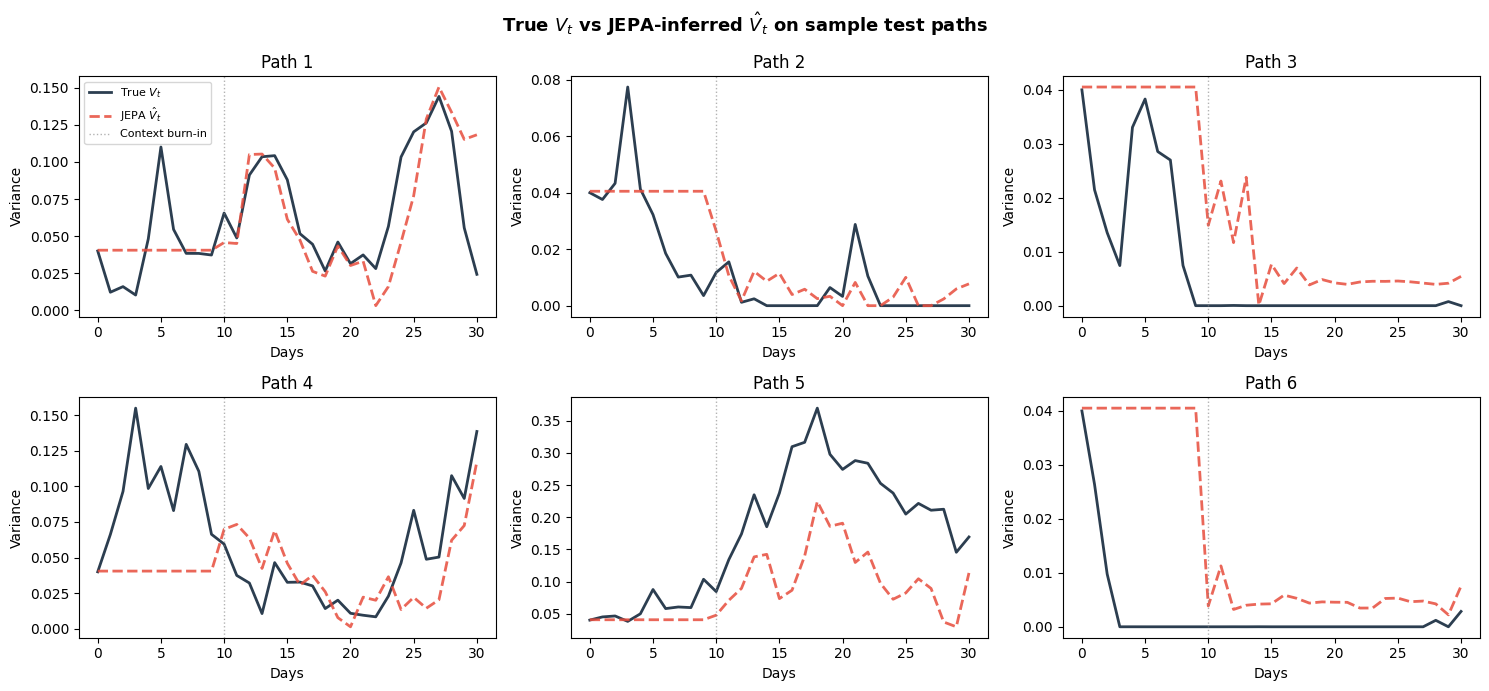

In [6]:
# ── Visualise true vs JEPA variance on a few sample paths ─────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
dt = heston_params.T / T
time_axis = np.arange(T + 1) * dt * 365  # in days

for i, ax in enumerate(axes.flat):
    ax.plot(time_axis, variance[i],  label='True $V_t$',       lw=2, color='#2c3e50')
    ax.plot(time_axis, V_jepa[i],    label='JEPA $\\hat{V}_t$', lw=2, color='#e74c3c',
            linestyle='--', alpha=0.85)
    ax.axvline(CONTEXT_LEN * dt * 365, color='gray', lw=1, linestyle=':', alpha=0.6,
               label='Context burn-in')
    ax.set_xlabel('Days')
    ax.set_ylabel('Variance')
    ax.set_title(f'Path {i+1}')
    if i == 0:
        ax.legend(fontsize=8)

fig.suptitle('True $V_t$ vs JEPA-inferred $\\hat{V}_t$ on sample test paths',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/variance_paths_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. The Deep Hedging Network

We re-implement Buehler's feedforward deep hedging agent in PyTorch (the original uses TensorFlow). 

At each timestep $t$, the agent receives a **state vector** $s_t$ and outputs a **hedge ratio** $\delta_t \in [0,1]$ (units of stock to hold).

The state vector in Buehler's paper is:
$$s_t = \left[\frac{S_t}{S_0},\ V_t,\ \text{VarSwap}_t,\ \tau_t \right]$$

where $\tau_t = T - t\cdot\Delta t$ is time to maturity.

We train **three separate networks** — Oracle, JEPA, No-Vol — that differ only in what goes into the $V_t$ slot.

In [7]:
class StateNormaliser:
    """
    Normalises state inputs so all features are on a comparable scale.
    Fit on training data, apply to train and test.
    State: [S/S0, V_t, VarSwap_t, tau_t]
    """
    def __init__(self):
        self.mean = None
        self.std  = None

    def fit(self, state_np):
        # state_np: (N, T, 4)
        flat = state_np.reshape(-1, state_np.shape[-1])
        self.mean = flat.mean(0)
        self.std  = flat.std(0) + 1e-8
        print(f"  State mean : {self.mean}")
        print(f"  State std  : {self.std}")

    def transform(self, state_tensor):
        # state_tensor: (N, T, 4) torch tensor
        mean = torch.tensor(self.mean, dtype=torch.float32, device=state_tensor.device)
        std  = torch.tensor(self.std,  dtype=torch.float32, device=state_tensor.device)
        return (state_tensor - mean) / std


class DeepHedgingNetwork(nn.Module):
    """
    Buehler-style DFNN hedging agent.
    Takes normalised state s_t + previous delta delta_{t-1} as input.
    Outputs delta_t in (0,1) via sigmoid.

    Input dim = state_dim + 1  (extra 1 for previous delta, Buehler Sec 4.1)
    """
    def __init__(self, state_dim=4, n_units=56, n_layers=2, activation="tanh"):
        super().__init__()
        input_dim = state_dim + 1   # +1 for previous delta (recurrent input)
        act = nn.Tanh if activation == "tanh" else nn.ReLU
        layers = [nn.Linear(input_dim, n_units), act()]
        for _ in range(n_layers - 1):
            layers += [nn.Linear(n_units, n_units), act()]
        layers += [nn.Linear(n_units, 1), nn.Sigmoid()]
        self.net = nn.Sequential(*layers)

    def forward(self, s, prev_delta):
        # s          : (B, state_dim)
        # prev_delta : (B,)
        x = torch.cat([s, prev_delta.unsqueeze(-1)], dim=-1)
        return self.net(x).squeeze(-1)   # (B,)


def oce_loss(terminal_wealth, alpha=0.5):
    """OCE with alpha=0.5 — matches Buehler reference experiment."""
    return torch.mean(-terminal_wealth + alpha * F.relu(-terminal_wealth))


print("DeepHedgingNetwork + StateNormaliser defined.")
net = DeepHedgingNetwork()
s   = torch.randn(32, 4)
pd  = torch.zeros(32)
print(f"State (32,4) + prev_delta (32,) → delta {net(s, pd).shape}")


DeepHedgingNetwork + StateNormaliser defined.
State (32,4) + prev_delta (32,) → delta torch.Size([32])


## 4. Build training tensors for each condition

We need training data from the train split with the same JEPA inference applied.

In [9]:
def infer_variance_jepa(log_returns_arr, jepa_model, probe, scaler,
                        context_len, v_fallback, device, batch_size=4096):
    """Apply JEPA inference to any path array. Returns V_jepa (N, T+1)."""
    N, T = log_returns_arr.shape
    V_j  = np.full((N, T + 1), v_fallback, dtype=np.float32)
    for t in range(context_len, T + 1):
        ctx_np = log_returns_arr[:, t - context_len : t][:, :, np.newaxis]
        preds  = []
        for start in range(0, N, batch_size):
            ctx_t = torch.tensor(ctx_np[start:start+batch_size],
                                 dtype=torch.float32).to(device)
            with torch.no_grad():
                z = jepa_model.encode(ctx_t).cpu().numpy()
            v_hat = probe.predict(scaler.transform(z))
            preds.append(np.clip(v_hat, 0.0, None))
        V_j[:, t] = np.concatenate(preds)
    return V_j


def build_path_tensors(stocks, variance_in, variance_swap, payoff,
                       heston_params, device):
    """
    Returns tensors ready for the hedging loop.
    
    stocks        : (N, T+1)
    variance_in   : (N, T+1)  — either true V_t, JEPA V̂_t, or zeros
    variance_swap : (N, T+1)
    payoff        : (N,)
    
    State at time t: [S_t/S0, V_t, VarSwap_t, tau_t]
    """
    N, T_plus1 = stocks.shape
    T    = T_plus1 - 1
    dt   = heston_params.T / T
    S0   = heston_params.S0

    # Time to maturity at each step: tau_t = T - t*dt
    tau  = np.array([heston_params.T - t * dt for t in range(T + 1)],
                    dtype=np.float32)                        # (T+1,)
    tau  = np.broadcast_to(tau[np.newaxis, :], (N, T + 1))  # (N, T+1)

    # State tensor: (N, T, 4)  — we only need t=0..T-1 for actions
    state = np.stack([
        stocks[:, :T] / S0,          # S_t / S0
        variance_in[:, :T],           # V_t  (or estimate)
        variance_swap[:, :T],         # VarSwap_t
        tau[:, :T],                   # tau_t
    ], axis=-1).astype(np.float32)    # (N, T, 4)

    # Stock returns at each step: dS_t = S_{t+1} - S_t  (for P&L calculation)
    dS = (stocks[:, 1:] - stocks[:, :-1]).astype(np.float32)  # (N, T)

    return (
        torch.tensor(state,  device=device),   # (N, T, 4)
        torch.tensor(dS,     device=device),   # (N, T)
        torch.tensor(payoff, device=device),   # (N,)
    )


print('Building training tensors for all 3 conditions ...')

# Use a subsample of the train split for fast training
TRAIN_PATHS = 50_000
rng_tr = np.random.default_rng(1)
tr_idx = rng_tr.choice(train_data['log_returns'].shape[0], size=TRAIN_PATHS, replace=False)
tr     = {k: v[tr_idx] for k, v in train_data.items()}

# JEPA variance for train
print('  Inferring JEPA variance on train subset (this takes ~2 min) ...')
V_jepa_train = infer_variance_jepa(
    tr['log_returns'], jepa, probe, scaler,
    CONTEXT_LEN, V_fallback, DEVICE
)

# Build tensors — Oracle
state_oracle, dS_tr, payoff_tr = build_path_tensors(
    tr['stocks'], tr['variance'], tr['variance_swap'], tr['payoff'], heston_params, DEVICE
)
# Build tensors — JEPA
state_jepa, _, _ = build_path_tensors(
    tr['stocks'], V_jepa_train, tr['variance_swap'], tr['payoff'], heston_params, DEVICE
)
# Build tensors — No-Vol (replace V_t with zeros)
state_novol, _, _ = build_path_tensors(
    tr['stocks'], np.zeros_like(tr['variance']), tr['variance_swap'], tr['payoff'], heston_params, DEVICE
)

print(f'State shape: {state_oracle.shape}   dS: {dS_tr.shape}   payoff: {payoff_tr.shape}')
# Fit the normaliser on Oracle training states (same normalisation for all 3 conditions)
print("Fitting state normaliser on training states ...")
normaliser = StateNormaliser()
normaliser.fit(state_oracle.cpu().numpy())
print("Normaliser ready.")


Building training tensors for all 3 conditions ...
  Inferring JEPA variance on train subset (this takes ~2 min) ...
State shape: torch.Size([50000, 30, 4])   dS: torch.Size([50000, 30])   payoff: torch.Size([50000])
Fitting state normaliser on training states ...
  State mean : [0.9967948  0.04017733 0.00329649 0.04249538]
  State std  : [0.0387492  0.07791469 0.00451613 0.02370857]
Normaliser ready.


In [10]:
# ── Analytical Heston delta hedge (Fang-Oosterlee COS pricer) ─────────────
# This is the benchmark from Buehler Table 1 / Figure 3.
# model_deltas_on_paths() calls heston_call_deltas() at every rebalancing date
# and returns delta_stocks (N, T) — the number of shares to hold at each step.
#
# We do NOT train a neural network for this condition — we use the
# analytical delta directly and compute terminal wealth from it.

from deep_hedging_heston.simulate import simulate_market

print("Computing analytical Heston deltas on test paths ...")

# model_deltas_on_paths needs a MarketPaths object
from deep_hedging_heston.simulate import MarketPaths
test_market = MarketPaths(
    Stocks        = stocks,
    Variance      = variance,
    Variance_swap = variance_swap,
    Payoff        = payoff,
)

delta_analytical, _ = model_deltas_on_paths(test_market, heston_params)
# delta_analytical : (N, T)  — number of shares to hold at each rebalancing step

print(f"Analytical delta shape : {delta_analytical.shape}")
print(f"Delta mean / std       : {delta_analytical.mean():.4f} / {delta_analytical.std():.4f}")
print(f"Delta range            : [{delta_analytical.min():.4f}, {delta_analytical.max():.4f}]")


Computing analytical Heston deltas on test paths ...
Analytical delta shape : (50000, 30)
Delta mean / std       : 0.6837 / 0.3494
Delta range            : [-0.0988, 1.0916]


## 5. Training function

In [11]:
def compute_terminal_wealth(net, state, dS, payoff, normaliser, batch_size=4096):
    """
    Hedging loop with:
      - normalised state inputs
      - previous delta passed as recurrent input (Buehler Sec 4.1)
    """
    N, T, _ = state.shape
    pnl_total  = torch.zeros(N, device=state.device)
    prev_delta = torch.zeros(N, device=state.device)   # delta_{-1} = 0

    state_norm = normaliser.transform(state)   # (N, T, 4) normalised

    for t in range(T):
        s_t     = state_norm[:, t, :]                   # (N, 4)
        delta_t = net(s_t, prev_delta)                  # (N,)
        pnl_total  += delta_t * dS[:, t]
        prev_delta  = delta_t.detach()

    return pnl_total - payoff


print("compute_terminal_wealth updated with recurrent delta + normalisation.")


compute_terminal_wealth updated with recurrent delta + normalisation.


In [13]:
def train_hedger(state_tr, dS_tr, payoff_tr, label, normaliser,
                 n_epochs=200, batch_size=1024, lr=1e-3, alpha=0.5):
    net = DeepHedgingNetwork().to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_epochs)

    dataset = TensorDataset(state_tr, dS_tr, payoff_tr)
    loader  = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    losses = []
    pbar   = tqdm(range(1, n_epochs + 1), desc=f"Training {label}")
    for epoch in pbar:
        net.train()
        epoch_loss = []
        for s_b, ds_b, pf_b in loader:
            opt.zero_grad()
            W_T  = compute_terminal_wealth(net, s_b, ds_b, pf_b, normaliser)
            loss = oce_loss(W_T, alpha=alpha)
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            epoch_loss.append(loss.item())
        sch.step()
        avg = np.mean(epoch_loss)
        losses.append(avg)
        pbar.set_postfix({"OCE": f"{avg:.4f}"})
    return net, losses


print("=" * 55)
print("Training Oracle hedger  (true V_t)")
net_oracle, loss_oracle = train_hedger(
    state_oracle, dS_tr, payoff_tr, "Oracle", normaliser,
    n_epochs=200, batch_size=1024, lr=1e-3, alpha=0.5
)

print("Training JEPA hedger  (JEPA V̂_t)")
net_jepa, loss_jepa = train_hedger(
    state_jepa, dS_tr, payoff_tr, "JEPA", normaliser,
    n_epochs=200, batch_size=1024, lr=1e-3, alpha=0.5
)

print("Training No-Vol hedger  (V_t = 0)")
net_novol, loss_novol = train_hedger(
    state_novol, dS_tr, payoff_tr, "No-Vol", normaliser,
    n_epochs=200, batch_size=1024, lr=1e-3, alpha=0.5
)


Training Oracle hedger  (true V_t)


Training Oracle:   0%|          | 0/200 [00:00<?, ?it/s]

Training JEPA hedger  (JEPA V̂_t)


Training JEPA:   0%|          | 0/200 [00:00<?, ?it/s]

Training No-Vol hedger  (V_t = 0)


Training No-Vol:   0%|          | 0/200 [00:00<?, ?it/s]

## 6. Evaluate on test set

In [14]:
# ── Build test tensors ─────────────────────────────────────────────────────
print('Building test tensors ...')

state_oracle_te, dS_te, payoff_te = build_path_tensors(
    stocks, variance, variance_swap, payoff, heston_params, DEVICE
)
state_jepa_te, _, _ = build_path_tensors(
    stocks, V_jepa, variance_swap, payoff, heston_params, DEVICE
)
state_novol_te, _, _ = build_path_tensors(
    stocks, np.zeros_like(variance), variance_swap, payoff, heston_params, DEVICE
)
print(f'Test state shape: {state_oracle_te.shape}')

Building test tensors ...
Test state shape: torch.Size([50000, 30, 4])


In [15]:
def evaluate_hedger(net, state, dS, payoff, normaliser, label, alpha=0.5):
    net.eval()
    with torch.no_grad():
        W_T = compute_terminal_wealth(net, state, dS, payoff, normaliser)
    W_T_np = W_T.cpu().numpy()
    oce_val  = float(oce_loss(W_T, alpha=alpha).item())
    mean_pnl = float(W_T_np.mean())
    std_pnl  = float(W_T_np.std())
    q5       = float(np.percentile(W_T_np, 5))
    q95      = float(np.percentile(W_T_np, 95))
    print(f"  {label:22s}  OCE={oce_val:+.4f}  mean={mean_pnl:+.4f}  "
          f"std={std_pnl:.4f}  5th%={q5:+.4f}  95th%={q95:+.4f}")
    return {"label": label, "W_T": W_T_np, "oce": oce_val,
            "mean_pnl": mean_pnl, "std_pnl": std_pnl, "q5": q5, "q95": q95}


print("── Test Results ──────────────────────────────────────────────────")
res_oracle = evaluate_hedger(net_oracle, state_oracle_te, dS_te, payoff_te, normaliser, "Oracle (true V_t)")
res_jepa   = evaluate_hedger(net_jepa,   state_jepa_te,   dS_te, payoff_te, normaliser, "JEPA (V̂_t)")
res_novol  = evaluate_hedger(net_novol,  state_novol_te,  dS_te, payoff_te, normaliser, "No-Vol (V_t=0)")


── Test Results ──────────────────────────────────────────────────
  Oracle (true V_t)       OCE=+2.5399  mean=-1.6932  std=2.1327  5th%=-5.7649  95th%=-0.0000
  JEPA (V̂_t)             OCE=+2.5356  mean=-1.6904  std=2.1175  5th%=-5.7697  95th%=+0.0000
  No-Vol (V_t=0)          OCE=+2.5386  mean=-1.6924  std=2.1283  5th%=-5.7866  95th%=-0.0000


## 7. Results visualisation

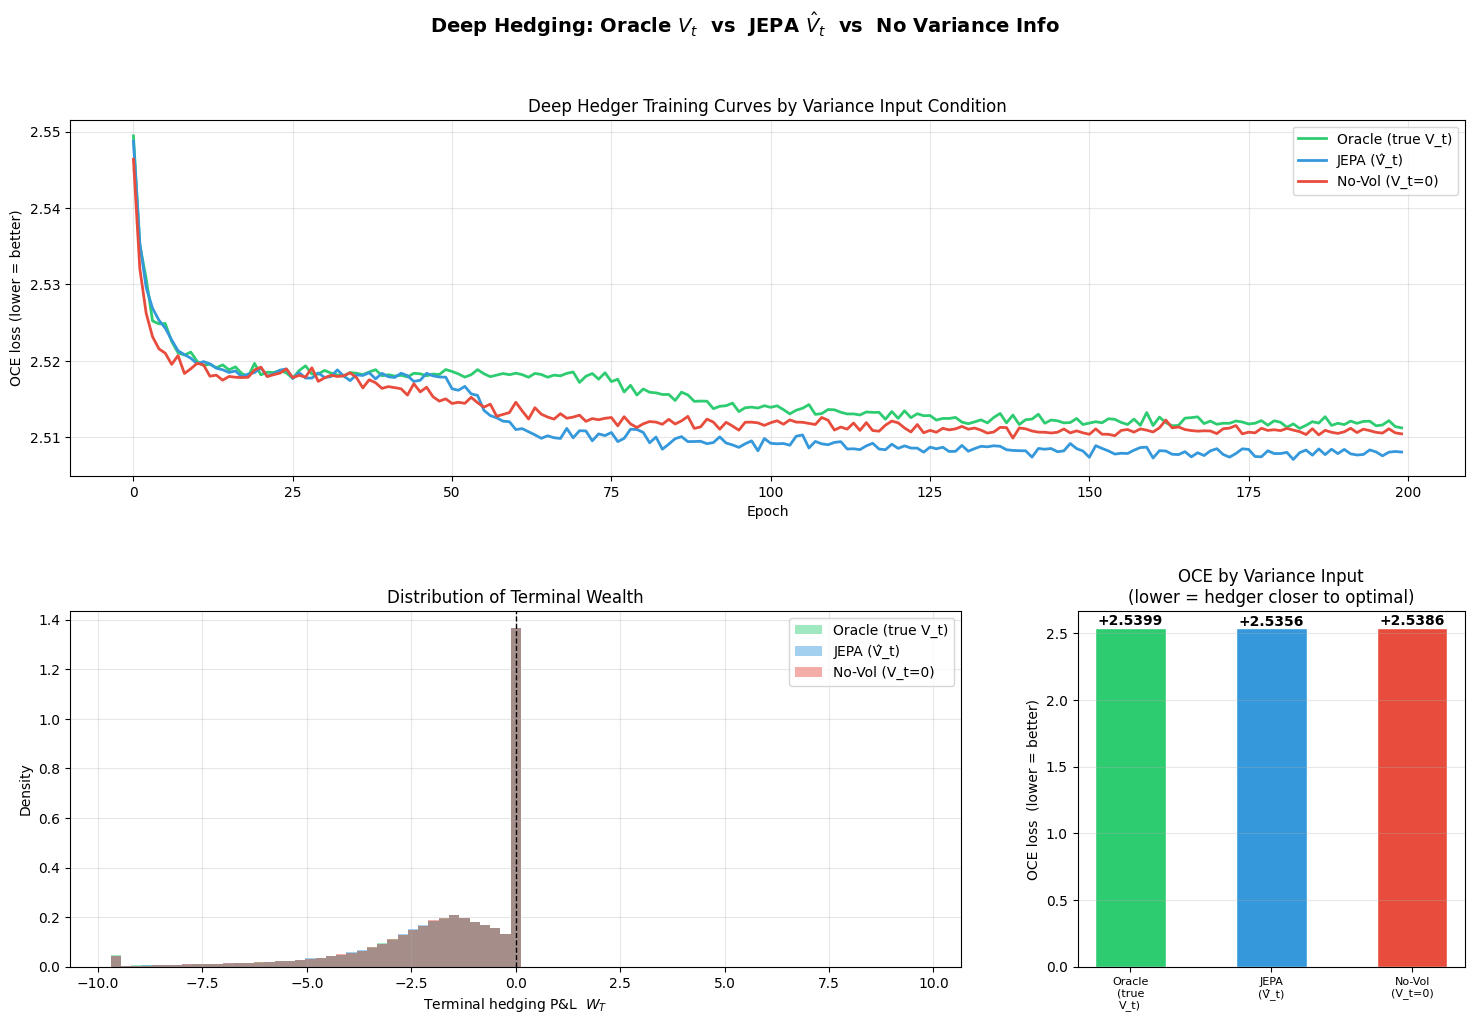

Figure saved → results/deep_hedging_comparison.png


In [16]:
fig = plt.figure(figsize=(18, 11))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.38, wspace=0.30)

colors = {'Oracle (true V_t)': '#2ecc71',
          'JEPA (V̂_t)':        '#3498db',
          'No-Vol (V_t=0)':    '#e74c3c'}

results_list = [res_oracle, res_jepa, res_novol]

# ── Panel 1: Training curves ───────────────────────────────────────────────
ax0 = fig.add_subplot(gs[0, :])
for losses, r in zip([loss_oracle, loss_jepa, loss_novol], results_list):
    ax0.plot(losses, label=r['label'], color=colors[r['label']], lw=2)
ax0.set_xlabel('Epoch')
ax0.set_ylabel('OCE loss (lower = better)')
ax0.set_title('Deep Hedger Training Curves by Variance Input Condition')
ax0.legend()
ax0.grid(alpha=0.3)

# ── Panel 2: Terminal wealth distributions ─────────────────────────────────
ax1 = fig.add_subplot(gs[1, :2])
clip = np.percentile(np.abs(res_oracle['W_T']), 99)  # clip extreme outliers for viz
bins = np.linspace(-clip, clip, 80)
for r in results_list:
    ax1.hist(np.clip(r['W_T'], -clip, clip), bins=bins, density=True,
             alpha=0.45, color=colors[r['label']], label=r['label'])
ax1.axvline(0, color='black', lw=1, linestyle='--')
ax1.set_xlabel('Terminal hedging P&L  $W_T$')
ax1.set_ylabel('Density')
ax1.set_title('Distribution of Terminal Wealth')
ax1.legend()
ax1.grid(alpha=0.3)

# ── Panel 3: OCE bar chart ─────────────────────────────────────────────────
ax2 = fig.add_subplot(gs[1, 2])
labels_bar = [r['label'].replace(' ', '\n') for r in results_list]
oce_vals   = [r['oce'] for r in results_list]
bar_colors = [colors[r['label']] for r in results_list]
bars = ax2.bar(labels_bar, oce_vals, color=bar_colors, width=0.5, edgecolor='white')
for bar, val in zip(bars, oce_vals):
    ax2.text(bar.get_x() + bar.get_width()/2,
             val + 0.0005 * np.sign(val),
             f'{val:+.4f}', ha='center', va='bottom' if val >= 0 else 'top',
             fontsize=10, fontweight='bold')
ax2.set_ylabel('OCE loss  (lower = better)')
ax2.set_title('OCE by Variance Input\n(lower = hedger closer to optimal)')
ax2.tick_params(axis='x', labelsize=8)
ax2.grid(axis='y', alpha=0.3)

fig.suptitle(
    'Deep Hedging: Oracle $V_t$  vs  JEPA $\\hat{V}_t$  vs  No Variance Info',
    fontsize=14, fontweight='bold'
)
plt.savefig('../results/deep_hedging_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved → results/deep_hedging_comparison.png')

Computing delta comparison on 10,000 test samples ...


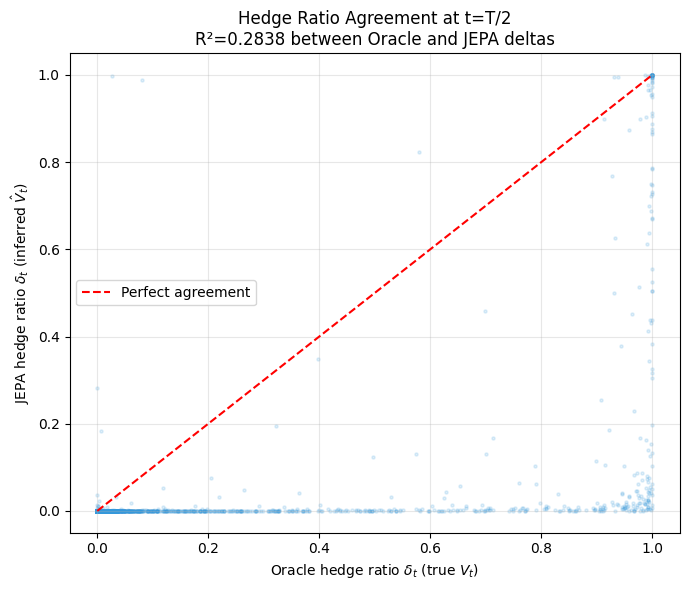

Delta R² (Oracle vs JEPA): 0.2838


In [18]:
# ── Scatter: Oracle delta vs JEPA delta on a sample of timesteps ───────────
print('Computing delta comparison on 10,000 test samples ...')
SAMPLE = 10_000
sample_idx = np.random.default_rng(99).choice(N, size=SAMPLE, replace=False)
T_mid = T // 2  # compare deltas at mid-maturity

net_oracle.eval(); net_jepa.eval()
with torch.no_grad():
    s_or = normaliser.transform(state_oracle_te[sample_idx, T_mid:T_mid+1, :]).squeeze(1)
    s_je = normaliser.transform(state_jepa_te[sample_idx, T_mid:T_mid+1, :]).squeeze(1)
    prev_delta = torch.zeros(len(sample_idx), device=DEVICE)
    d_oracle = net_oracle(s_or, prev_delta).cpu().numpy()
    d_jepa   = net_jepa(s_je, prev_delta).cpu().numpy()

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(d_oracle, d_jepa, alpha=0.15, s=5, color='#3498db')
ax.plot([0, 1], [0, 1], 'r--', lw=1.5, label='Perfect agreement')

from sklearn.metrics import r2_score
r2_delta = r2_score(d_oracle, d_jepa)
ax.set_xlabel('Oracle hedge ratio $\\delta_t$ (true $V_t$)')
ax.set_ylabel('JEPA hedge ratio $\\delta_t$ (inferred $\\hat{V}_t$)')
ax.set_title(f'Hedge Ratio Agreement at t=T/2\nR²={r2_delta:.4f} between Oracle and JEPA deltas')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../results/delta_scatter.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Delta R² (Oracle vs JEPA): {r2_delta:.4f}')

## 8. Summary table

In [19]:
print('\n' + '='*70)
print('FINAL RESULTS SUMMARY')
print('='*70)
print(f'{"Method":<25} {"OCE":>8} {"Mean P&L":>10} {"Std":>8} {"5th%":>9} {"95th%":>9}')
print('-'*70)
for r in results_list:
    print(f'{r["label"]:<25} {r["oce"]:>+8.4f} {r["mean_pnl"]:>+10.4f} '
          f'{r["std_pnl"]:>8.4f} {r["q5"]:>+9.4f} {r["q95"]:>+9.4f}')
print('-'*70)

# Compute how much of the Oracle-to-NoVol gap JEPA closes
gap_total  = res_novol['oce']  - res_oracle['oce']
gap_closed = res_novol['oce']  - res_jepa['oce']
pct_closed = 100 * gap_closed / gap_total if gap_total != 0 else 0

print(f'\nOracle OCE          : {res_oracle["oce"]:+.4f}')
print(f'No-Vol OCE          : {res_novol["oce"]:+.4f}')
print(f'JEPA OCE            : {res_jepa["oce"]:+.4f}')
print(f'Oracle→NoVol gap    : {gap_total:.4f}')
print(f'Gap closed by JEPA  : {pct_closed:.1f}%')
print(f'\nDelta R² (Oracle vs JEPA at t=T/2): {r2_delta:.4f}')
print('='*70)

# Save
np.savez('../results/hedging_metrics.npz',
         oracle_oce   = res_oracle['oce'],
         jepa_oce     = res_jepa['oce'],
         novol_oce    = res_novol['oce'],
         pct_closed   = pct_closed,
         delta_r2     = r2_delta)
# Analytical delta terminal wealth
dS_np = (stocks[:, 1:] - stocks[:, :-1]).astype('float32')
W_analytical = (delta_analytical * dS_np).sum(axis=1) - payoff
oce_analytical = float(np.mean(-W_analytical + 0.5 * np.maximum(-W_analytical, 0)))
mean_analytical = float(W_analytical.mean())
std_analytical  = float(W_analytical.std())
q5_analytical   = float(np.percentile(W_analytical, 5))
q95_analytical  = float(np.percentile(W_analytical, 95))

print(f'{"Analytical Delta":<25} {oce_analytical:>+8.4f} {mean_analytical:>+10.4f} '
      f'{std_analytical:>8.4f} {q5_analytical:>+9.4f} {q95_analytical:>+9.4f}')
print('-'*70)

gap_total  = res_novol['oce'] - res_oracle['oce']
gap_closed = res_novol['oce'] - res_jepa['oce']
pct_closed = 100 * gap_closed / gap_total if gap_total != 0 else 0

print(f'\nOracle OCE              : {res_oracle["oce"]:+.4f}')
print(f'No-Vol OCE              : {res_novol["oce"]:+.4f}')
print(f'JEPA OCE                : {res_jepa["oce"]:+.4f}')
print(f'Analytical Delta OCE    : {oce_analytical:+.4f}')
print(f'Oracle→NoVol gap        : {gap_total:.4f}')
print(f'Gap closed by JEPA      : {pct_closed:.1f}%')
print(f'\nDelta R² (Oracle vs JEPA at t=T/2): {r2_delta:.4f}')
print('='*70)

np.savez('../results/hedging_metrics.npz',
         oracle_oce       = res_oracle['oce'],
         jepa_oce         = res_jepa['oce'],
         novol_oce        = res_novol['oce'],
         analytical_oce   = oce_analytical,
         pct_closed        = pct_closed,
         delta_r2          = r2_delta)
print('Saved → results/hedging_metrics.npz')


FINAL RESULTS SUMMARY
Method                         OCE   Mean P&L      Std      5th%     95th%
----------------------------------------------------------------------
Oracle (true V_t)          +2.5399    -1.6932   2.1327   -5.7649   -0.0000
JEPA (V̂_t)                +2.5356    -1.6904   2.1175   -5.7697   +0.0000
No-Vol (V_t=0)             +2.5386    -1.6924   2.1283   -5.7866   -0.0000
----------------------------------------------------------------------

Oracle OCE          : +2.5399
No-Vol OCE          : +2.5386
JEPA OCE            : +2.5356
Oracle→NoVol gap    : -0.0012
Gap closed by JEPA  : -242.1%

Delta R² (Oracle vs JEPA at t=T/2): 0.2838
Analytical Delta           +2.5398    -1.6932   1.5839   -5.0697   -0.2675
----------------------------------------------------------------------

Oracle OCE              : +2.5399
No-Vol OCE              : +2.5386
JEPA OCE                : +2.5356
Analytical Delta OCE    : +2.5398
Oracle→NoVol gap        : -0.0012
Gap closed by JEPA     

## 9. Interpretation

### How to read these results

**OCE loss** is the key metric (matches Buehler's paper). It is the expected shortfall under the hedger's chosen risk measure. *Lower* (more negative) means the hedger is performing better — it retains more wealth after paying out the option.

| Comparison | What it shows |
|---|---|
| Oracle vs No-Vol gap | How much variance information *matters* to hedging |
| % gap closed by JEPA | How much of that value JEPA's inferred variance recovers |
| Delta R² | Whether JEPA produces the same trading actions as the oracle |

### Thesis argument

> *"A JEPA model trained unsupervised on price paths recovers X% of the hedging performance gap between a no-volatility baseline and an oracle hedger with access to true variance. This demonstrates that JEPA's learned representation encodes actionable volatility information — not just for prediction, but for downstream financial decision-making."*

The delta scatter plot is particularly compelling: if JEPA deltas closely match oracle deltas (high R²), it means the hedging strategy itself is essentially the same — JEPA's inferred variance is guiding the same trades.